# interpolation_grid_station 方法说明

将源格点场插值到站点位置。包内三个插件：

| 插件 | 典型用途 |
| --- | --- |
| `InterpGsLinear` | 双线性；`used_coords` 支持 `xy` / `xyz` / `xydt` |
| `InterpGsNearest` | 最近邻；索引四舍五入 |
| `InterpGsCubic` | 双三次；三次卷积核加权 |

在包根或本 `nbs/` 目录打开本 notebook 即可运行示例（依赖 `meteva_base`，样例数据在 `resource/`）。


In [1]:
from __future__ import annotations

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import meteva_base as meb
import numpy as np
import pandas as pd
from meteva_base.tool.color_tools import (
    def_cmap_clevs,
    get_cmap_and_clevs_by_element_name,
)

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

PACKAGE_ROOT = Path.cwd().resolve()
if PACKAGE_ROOT.name == "nbs":
    PACKAGE_ROOT = PACKAGE_ROOT.parent
DATA_DIR = PACKAGE_ROOT / "resource"

src_s, root_s = str(PACKAGE_ROOT / "src"), str(PACKAGE_ROOT)
for p in (src_s, root_s):
    if p in sys.path:
        sys.path.remove(p)
sys.path.insert(0, src_s)
sys.path.insert(0, root_s)

from interp_gs_cubic_plugin import InterpGsCubic
from interp_gs_linear_plugin import InterpGsLinear
from interp_gs_nearest_plugin import InterpGsNearest


d:\workspace\test\.venv\Lib\site-packages\meteva_base\basicdata\const.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


## 1. 原理

接口统一为 `process(grd, sta)`：`grd` 为源六维场，`sta` 为目标站点表（至少含 `lon` / `lat`；`id` 等列保留）。

| 方法 | 原理 |
| --- | --- |
| **InterpGsLinear** | 水平四邻点双线性；`xyz` 再叠一层高度线性；`xydt` 再叠一层时效线性 |
| **InterpGsNearest** | 索引 `np.round` 到最近源格点赋值 |
| **InterpGsCubic** | 邻域 `p,q ∈ {-1,0,1,2}`，三次核加权 |

共同约定：

- 网格外站点由 `in_grid_xy` / `in_grid_xyz` 剔除；无有效站点时返回 `None`。
- `member` / `level` / `time` / `dtime` 展开为站点表行；数据列名为 `member` 坐标值。
- `attrs` 深拷贝自源场。
- Linear 插值前会做经度范围对齐与全球经度扩展（与 `utils.interpolating.interp_gs_linear` 一致）。

`used_coords` 含义：

| 取值 | 含义 |
| --- | --- |
| `xy` | 仅 lon/lat |
| `xyz` | lon/lat + 站点自身 `level` |
| `xydt` | lon/lat + 站点自身 `dtime`（源场 dtime 维 ≥ 2） |


## 2. 参数

| 参数 | 位置 | 说明 |
| --- | --- | --- |
| `used_coords` | 构造 / `process` | Linear：`xy`/`xyz`/`xydt`；Nearest/Cubic：仅 `xy` |
| `grd` | `process` | 源格点场 |
| `sta` | `process` | 目标站点表 |

CLI（在包目录）：`python -m cli --module linear|nearest|cubic ...`，缺省读 `resource/conf.ini`。  
站点 `csv|m3`，格点 `nc|m4`，可用 `--sta-type` / `--grid-type` / `--output` 控制读写。


## 3. 读入样例数据

- 源格点：`resource/2026100900.024.nc`（约 0.1°，60–140°E / 0–60°N）
- 目标站点：`resource/2026100900.024_sta.csv`（334 站；`time`/`dtime`/`level` 已与 nc 对齐）

读入站点时若出现提示：

> 站点数据缺属性说明，已自动赋值默认值，使用需谨慎

来自 **`meb.read_stadata_from_csv`**：CSV 未带 meb 属性头（`units` / `model_var` / `dtime_units` 等）时，会写入默认 attrs。本样例 CSV 为普通表头，属预期行为；后续检验若依赖单位/模式名，请补全属性头或自行 `set_stadata_attrs`。

**插值输出图怎么看**

- 底色：源格点场（`add_contourf`），颜色对应格点值。
- 散点：插到站点后的值（黑边圆点叠在底图上），与底图共用同一套 `cmap`/`clevs`；无数值时为黑点标位。
- 对比：点色应接近所在位置的格点底色；Nearest 更“贴格点”、Linear/Cubic 更平滑。色阶按样例场实测范围裁剪，避免全库 `temp` 默认 -50~44 过宽。


level,time,dtime,id,lon,lat,data0

站点数据缺属性说明，已自动赋值默认值，使用需谨慎
<xarray.DataArray 'data0' (member: 1, level: 1, time: 1, dtime: 1, lat: 69,
                           lon: 209)> Size: 58kB
array([[[[[[ -2.9,  -0.7,   0.5, ...,  20. ,  19.8,  19.7],
           [ -0.4,   1.3,   1.4, ...,  20.1,  20.2,  20.2],
           [  0.3,   0.5,  -0.9, ...,  20.3,  20.5,  20.5],
           ...,
           [ -9.9, -10.7, -11.3, ...,  20.4,  20.3,  20.2],
           [ -8.6, -10.8, -12.9, ...,  20.5,  20.4,  20.2],
           [ -9.8, -12.5, -13.8, ...,  20.5,  20.4,  20.3]]]]]],
      shape=(1, 1, 1, 1, 69, 209), dtype=float32)
Coordinates:
  * member   (member) <U5 20B 'data0'
  * level    (level) float32 4B 0.0
  * time     (time) datetime64[ns] 8B 2026-10-09
  * dtime    (dtime) int32 4B 24
  * lat      (lat) float64 552B 31.6 31.7 31.8 31.9 32.0 ... 38.1 38.2 38.3 38.4
  * lon      (lon) float64 2kB 99.6 99.7 99.8 99.9 ... 120.1 120.2 120.3 120.4
Attributes:
    units:        degC
    model_var:    
 

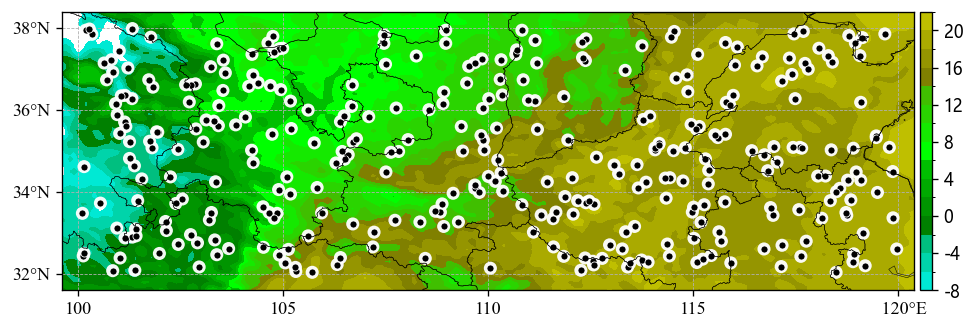

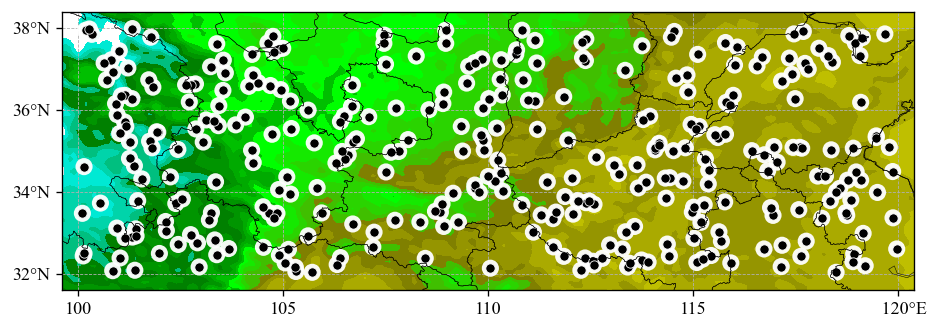

In [2]:
GRID_PATH = DATA_DIR / "2026100900.024.nc"
STA_PATH = DATA_DIR / "2026100900.024_sta.csv"

grd_in = meb.read_griddata_from_nc(str(GRID_PATH))
sta = meb.read_stadata_from_csv(str(STA_PATH))
# 裁到站点覆盖域附近，便于对比
grd_cut = grd_in.sel(
    lon=slice(float(sta["lon"].min()) - 0.5, float(sta["lon"].max()) + 0.5),
    lat=slice(float(sta["lat"].min()) - 0.5, float(sta["lat"].max()) + 0.5),
)
print(grd_cut)
print(sta)
print("nsta =", len(sta))
print("sta time/dtime =", sta["time"].iloc[0], int(sta["dtime"].iloc[0]))


def map_extend_from_grd(grd, pad=0.0):
    lon0, lon1 = float(grd["lon"].values.min()), float(grd["lon"].values.max())
    lat0, lat1 = float(grd["lat"].values.min()), float(grd["lat"].values.max())
    return [lon0 - pad, lon1 + pad, lat0 - pad, lat1 + pad]


def clevs_for_temp(grd, *sta_list, max_levels=16):
    """用 temp 色表，按数据范围裁剪并适当抽稀，避免默认 -50~44 分级过密。"""
    cmap_all, clevs_all = get_cmap_and_clevs_by_element_name("temp")
    vals = [np.asarray(grd.values, dtype=float).ravel()]
    for s in sta_list:
        if s is None or len(s) == 0:
            continue
        names = meb.get_stadata_names(s)
        if names:
            vals.append(np.asarray(s[names[-1]].values, dtype=float).ravel())
    z = np.concatenate(vals)
    z = z[np.isfinite(z)]
    vmin = float(np.nanpercentile(z, 1))
    vmax = float(np.nanpercentile(z, 99))
    cmap, clevs = def_cmap_clevs(
        cmap=cmap_all, clevs=clevs_all, vmin=vmin, vmax=vmax, cut_colorbar=True
    )
    clevs = np.asarray(clevs, dtype=float)
    if len(clevs) > max_levels:
        step = int(np.ceil((len(clevs) - 1) / (max_levels - 1)))
        clevs = clevs[::step]
        end = clevs_all[clevs_all <= vmax + 1e-6]
        if len(end) and clevs[-1] != end[-1]:
            clevs = np.unique(np.append(clevs, end[-1]))
        cmap, clevs = def_cmap_clevs(
            cmap=cmap_all, clevs=clevs, vmin=clevs[0], vmax=clevs[-1], cut_colorbar=True
        )
    return cmap, np.asarray(clevs, dtype=float)


# 全 notebook 共用一套色阶（源场 + 各方法插值结果）
CMAP, CLEVS = clevs_for_temp(grd_cut)
MAP_EXTEND = map_extend_from_grd(grd_cut)
print("clevs =", CLEVS)


def _add_colorbar(ax, mappable):
    fig = plt.gcf()
    width = fig.bbox.width / fig.dpi
    height = fig.bbox.height / fig.dpi
    loc = [
        ax.bbox.x1 / fig.dpi / width + 0.005,
        ax.bbox.y0 / fig.dpi / height,
        0.01,
        ax.bbox.height / fig.dpi / height,
    ]
    cax = fig.add_axes(loc)
    return fig.colorbar(mappable, cax=cax)


def add_station_markers(ax, sta_df, cmap=None, clevs=None, add_colorbar=True, size=42):
    """在 meb 底图上叠站点：白底光晕 + 黑边，避免与 contourf 同色融在一起。"""
    from matplotlib.colors import BoundaryNorm

    names = meb.get_stadata_names(sta_df)
    lon = sta_df["lon"].to_numpy(dtype=float)
    lat = sta_df["lat"].to_numpy(dtype=float)
    # 白底光晕，保证站点在同色底图上仍可辨
    ax.scatter(lon, lat, s=size * 2.2, c="w", edgecolors="none", zorder=5, alpha=0.95)
    has_val = bool(names) and np.isfinite(sta_df[names[-1]].astype(float)).any()
    if has_val:
        cmap = CMAP if cmap is None else cmap
        clevs = np.asarray(CLEVS if clevs is None else clevs, dtype=float)
        vals = sta_df[names[-1]].astype(float).to_numpy()
        norm = BoundaryNorm(clevs, ncolors=cmap.N - 1)
        im = ax.scatter(
            lon,
            lat,
            c=vals,
            cmap=cmap,
            norm=norm,
            s=size,
            edgecolors="k",
            linewidths=0.7,
            zorder=6,
        )
        if add_colorbar:
            _add_colorbar(ax, im)
        return im
    ax.scatter(
        lon,
        lat,
        s=size * 0.65,
        c="k",
        edgecolors="w",
        linewidths=0.5,
        zorder=6,
        label="station",
    )
    return None


def plot_source_field(grd, sta_df=None, title="源场", cmap=None, clevs=None, map_extend=None):
    """源场底色；若传入 sta_df，叠黑点标出目标站位。"""
    cmap = CMAP if cmap is None else cmap
    clevs = CLEVS if clevs is None else clevs
    map_extend = MAP_EXTEND if map_extend is None else map_extend
    axs = meb.creat_axs(1, map_extend, ncol=1, height=8, width=10, dpi=120, add_index=[title])
    meb.add_contourf(axs[0], grd, cmap=cmap, clevs=clevs, add_colorbar=True)
    if sta_df is not None:
        add_station_markers(axs[0], sta_df, add_colorbar=False, size=28)
    plt.show()


def plot_interp_result(grd, sta_df, title="插值结果", cmap=None, clevs=None, map_extend=None):
    """底图源场 + 站点填色（同一色阶，黑边突出站点）。"""
    cmap = CMAP if cmap is None else cmap
    clevs = CLEVS if clevs is None else clevs
    map_extend = MAP_EXTEND if map_extend is None else map_extend
    axs = meb.creat_axs(1, map_extend, ncol=1, height=8, width=10, dpi=120, add_index=[title])
    meb.add_contourf(axs[0], grd, cmap=cmap, clevs=clevs, add_colorbar=False)
    add_station_markers(axs[0], sta_df, cmap=cmap, clevs=clevs, add_colorbar=True, size=48)
    plt.show()


def plot_method_compare(grd, sta_dict, cmap=None, clevs=None, map_extend=None):
    """creat_axs 多面板对比多种插值结果。"""
    cmap = CMAP if cmap is None else cmap
    clevs = CLEVS if clevs is None else clevs
    map_extend = MAP_EXTEND if map_extend is None else map_extend
    titles = list(sta_dict.keys())
    n = len(titles)
    axs = meb.creat_axs(
        n,
        map_extend,
        ncol=n,
        height=7,
        width=7 * n,
        dpi=110,
        add_index=titles,
        wspace=0.8,
        sup_title="格点→站点插值对比",
        sup_fontsize=14,
    )
    for i, name in enumerate(titles):
        meb.add_contourf(axs[i], grd, cmap=cmap, clevs=clevs, add_colorbar=False)
        add_station_markers(
            axs[i],
            sta_dict[name],
            cmap=cmap,
            clevs=clevs,
            add_colorbar=(i == n - 1),
            size=36,
        )
    plt.show()


# 源场 + 目标站位（黑点）；仅站位图见下一调用
plot_source_field(
    grd_cut,
    sta_df=sta[["level", "time", "dtime", "id", "lon", "lat"]],
    title="源场+目标站位",
)
plot_interp_result(
    grd_cut,
    sta[["level", "time", "dtime", "id", "lon", "lat"]],
    title="目标站位",
)


## 4. 插件调用示例

### 4.1 InterpGsLinear


     level       time  dtime     id     lon    lat      data0
0      0.0 2026-10-09     24  50000  112.37  32.39  17.520999
1      0.0 2026-10-09     24  50003  112.27  32.09  17.439000
2      0.0 2026-10-09     24  50006  110.24  34.78  16.580000
3      0.0 2026-10-09     24  50009  108.84  33.51  13.180000
4      0.0 2026-10-09     24  50012  112.08  33.46  17.284000
..     ...        ...    ...    ...     ...    ...        ...
329    0.0 2026-10-09     24  50987  101.25  34.82  -2.450000
330    0.0 2026-10-09     24  50990  110.83  33.69  15.614000
331    0.0 2026-10-09     24  50993  117.06  34.73  18.012000
332    0.0 2026-10-09     24  50996  111.85  36.33  14.965000
333    0.0 2026-10-09     24  50999  102.95  32.17   1.430000

[334 rows x 7 columns]


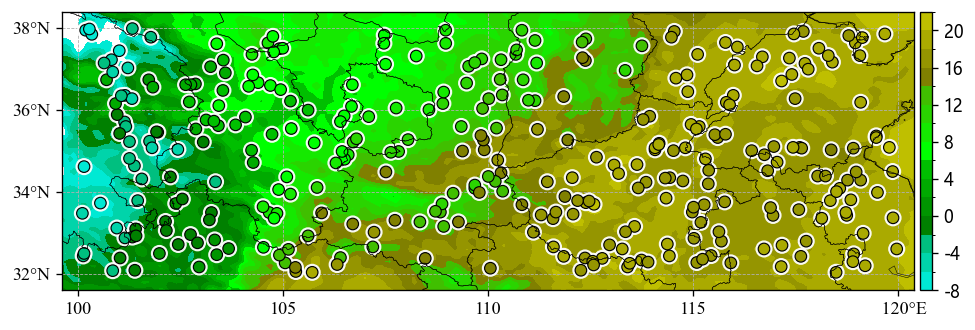

In [3]:
sta_linear = InterpGsLinear(used_coords="xy").process(grd_in, sta)
print(sta_linear)
plot_interp_result(grd_cut, sta_linear, title="InterpGsLinear")


### 4.2 InterpGsNearest


     level       time  dtime     id     lon    lat      data0
0      0.0 2026-10-09     24  50000  112.37  32.39  17.299999
1      0.0 2026-10-09     24  50003  112.27  32.09  17.400000
2      0.0 2026-10-09     24  50006  110.24  34.78  16.500000
3      0.0 2026-10-09     24  50009  108.84  33.51  13.600000
4      0.0 2026-10-09     24  50012  112.08  33.46  16.500000
..     ...        ...    ...    ...     ...    ...        ...
329    0.0 2026-10-09     24  50987  101.25  34.82  -2.400000
330    0.0 2026-10-09     24  50990  110.83  33.69  15.600000
331    0.0 2026-10-09     24  50993  117.06  34.73  18.200001
332    0.0 2026-10-09     24  50996  111.85  36.33  15.700000
333    0.0 2026-10-09     24  50999  102.95  32.17   1.700000

[334 rows x 7 columns]


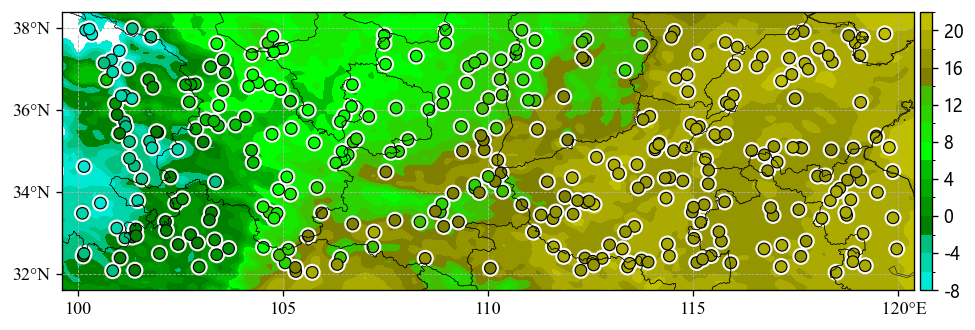

In [4]:
sta_nearest = InterpGsNearest().process(grd_in, sta)
print(sta_nearest)
plot_interp_result(grd_cut, sta_nearest, title="InterpGsNearest")


### 4.3 InterpGsCubic


     level       time  dtime     id     lon    lat      data0
0      0.0 2026-10-09     24  50000  112.37  32.39  17.499720
1      0.0 2026-10-09     24  50003  112.27  32.09  17.419066
2      0.0 2026-10-09     24  50006  110.24  34.78  16.540781
3      0.0 2026-10-09     24  50009  108.84  33.51  13.144614
4      0.0 2026-10-09     24  50012  112.08  33.46  17.152749
..     ...        ...    ...    ...     ...    ...        ...
329    0.0 2026-10-09     24  50987  101.25  34.82  -2.306600
330    0.0 2026-10-09     24  50990  110.83  33.69  15.746432
331    0.0 2026-10-09     24  50993  117.06  34.73  18.069570
332    0.0 2026-10-09     24  50996  111.85  36.33  15.044056
333    0.0 2026-10-09     24  50999  102.95  32.17   1.547628

[334 rows x 7 columns]


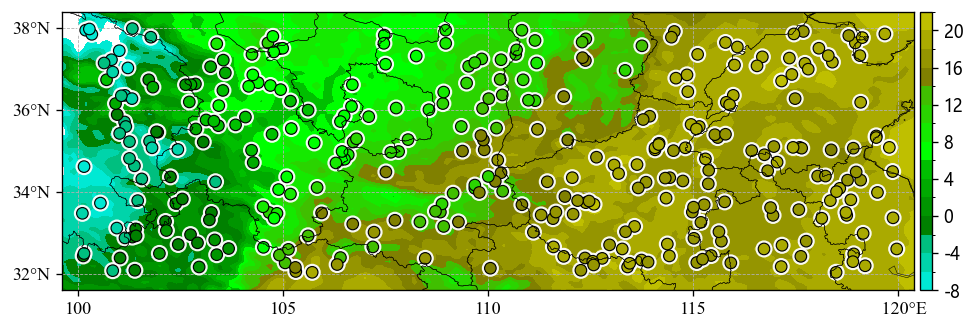

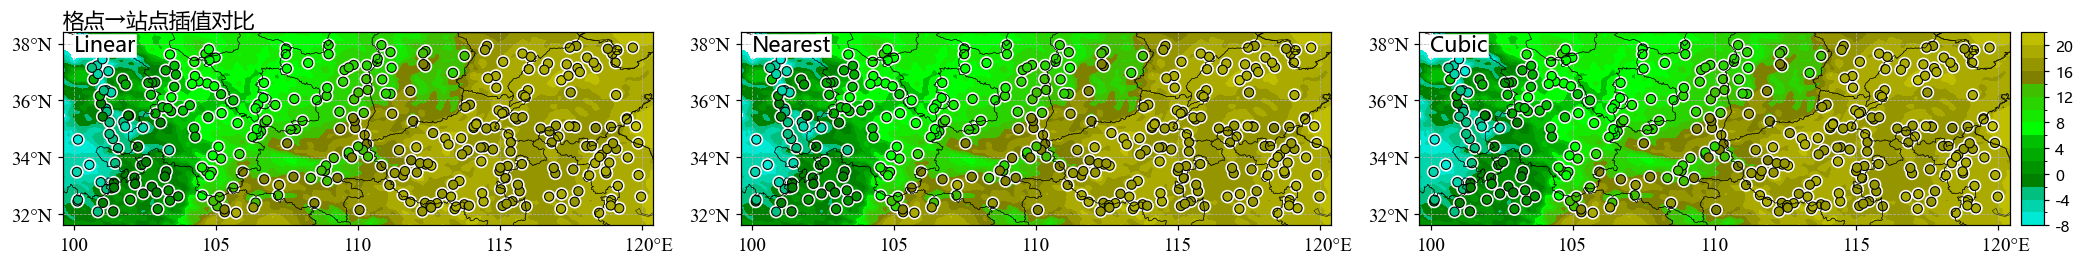

In [5]:
sta_cubic = InterpGsCubic().process(grd_in, sta)
print(sta_cubic)
plot_interp_result(grd_cut, sta_cubic, title="InterpGsCubic")

# 三方法对比：creat_axs 统一底图 + 同一色阶
plot_method_compare(
    grd_cut,
    {
        "Linear": sta_linear,
        "Nearest": sta_nearest,
        "Cubic": sta_cubic,
    },
)


### 4.4 InterpGsLinear：`used_coords="xydt"`（合成多时效场）

样例 nc 只有 1 个 dtime，无法直接做 `xydt`。下面用合成场演示：水平 + 时效可分离线性，场为 `f = lon + 0.1*lat + 0.01*dtime`。


In [ ]:
grid_dt = meb.grid(
    [100, 104, 1.0],
    [20, 22, 1.0],
    gtime=["2020010100"],
    dtime_list=[0, 3, 6],
    level_list=[0],
    member_list=["data0"],
)
grd_dt = meb.grid_data(grid_dt)
lon = grd_dt["lon"].values
lat = grd_dt["lat"].values
for k, dt in enumerate(grd_dt["dtime"].values.astype(float)):
    lon2d, lat2d = np.meshgrid(lon, lat)
    grd_dt.values[0, 0, 0, k, :, :] = lon2d + 0.1 * lat2d + 0.01 * float(dt)    

sta_dt = pd.DataFrame(
    {
        "level": [0, 0],
        "time": [pd.Timestamp("2020-01-01")] * 2,
        "dtime": [1.5, 3.0],
        "id": [1, 2],
        "lon": [100.5, 102.0],
        "lat": [20.5, 21.0],
        "data0": [np.nan, np.nan],
    }
)
out_dt = InterpGsLinear(used_coords="xydt").process(grd_dt, sta_dt)
expect = out_dt["lon"] + 0.1 * out_dt["lat"] + 0.01 * out_dt["dtime"]
print(out_dt)
err = float(np.nanmax(np.abs(out_dt["data0"].astype(float) - expect)))
print("max |err| =", err)  # float32 场约 1e-6 量级


   level       time  dtime  id    lon   lat       data0
0    0.0 2020-01-01    1.5   1  100.5  20.5  102.564999
1    0.0 2020-01-01    3.0   2  102.0  21.0  104.129997
max |err| = 2.7465820267025265e-06


## 5. CLI 使用示例

在包目录等价于：

```bash
python -m cli --module linear --grid resource/2026100900.024.nc --sta resource/2026100900.024_sta.csv --output resource/cli_linear_out.csv
```

下面用 `InterpolationGridStationCli.call` 调度，输出写到 `resource/`，再读回绘图对比。

csv 直接使用 `meb.write_stadata_to_csv` / `read_stadata_from_csv`。


level,time,dtime,id,lon,lat,data0

站点数据缺属性说明，已自动赋值默认值，使用需谨慎
写出 → D:\workspace\test\00temp\interpolation_grid_station\resource\cli_linear_out.csv
     level       time  dtime     id     lon    lat      data0
0      0.0 2026-10-09     24  50000  112.37  32.39  17.520999
1      0.0 2026-10-09     24  50003  112.27  32.09  17.439000
2      0.0 2026-10-09     24  50006  110.24  34.78  16.580000
3      0.0 2026-10-09     24  50009  108.84  33.51  13.180000
4      0.0 2026-10-09     24  50012  112.08  33.46  17.284000
..     ...        ...    ...    ...     ...    ...        ...
329    0.0 2026-10-09     24  50987  101.25  34.82  -2.450000
330    0.0 2026-10-09     24  50990  110.83  33.69  15.614000
331    0.0 2026-10-09     24  50993  117.06  34.73  18.012000
332    0.0 2026-10-09     24  50996  111.85  36.33  14.965000
333    0.0 2026-10-09     24  50999  102.95  32.17   1.430000

[334 rows x 7 columns]
return code = 0
output = D:\workspace\test\00temp\interpolation_grid_station\resource\c

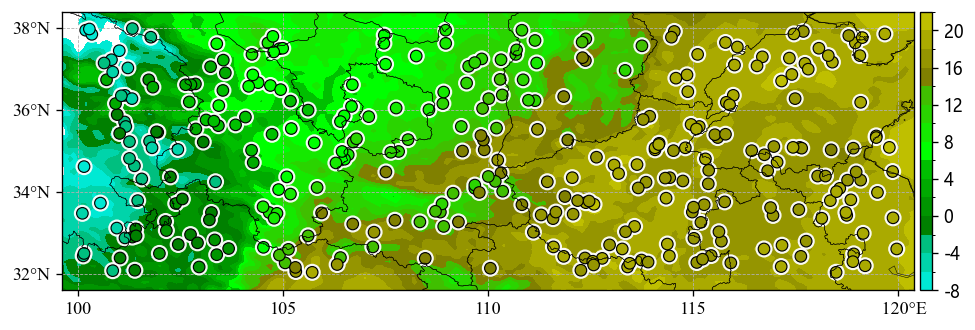

In [7]:
from cli.interpolation_grid_station_cli import InterpolationGridStationCli

out_csv = str(DATA_DIR / "cli_linear_out.csv")
rc = InterpolationGridStationCli.call(
    module="linear",
    grid=str(GRID_PATH),
    sta=str(STA_PATH),
    output=out_csv,
    used_coords="xy",
    grid_type="nc",
    sta_type="csv",
    output_type="csv",
)
print("return code =", rc)
print("output =", out_csv)

sta_cli = meb.read_stadata_from_csv(out_csv)
print(sta_cli)
print("attrs =", dict(sta_cli.attrs))
plot_interp_result(grd_cut, sta_cli, title="CLI InterpGsLinear")


## 6. 小结

- 插件接口统一：`process(grd, sta)`；Nearest / Cubic 仅 `xy`，Linear 另支持 `xyz` / `xydt`。
- 样例：`resource/2026100900.024.nc` + `resource/2026100900.024_sta.csv`（334 站，时空与 nc 对齐）。
- 读站 CSV 无属性头时，`meb.read_stadata_from_csv` 会打印「站点数据缺属性说明…」并赋默认 attrs。
- 绘图优先用 `meb.creat_axs` + `add_contourf` / `add_scatter`；色阶用 `temp` 色表按数据范围裁剪。
- CLI：`python -m cli --module linear|nearest|cubic`，输出示例见 `resource/cli_linear_out.csv`；格点 `nc|m4`，站点 `csv|m3`。
- 选型：一般检验/对比用 Linear；要保持格点原值突变用 Nearest；要更平滑用 Cubic。
